# Chapter 03 — Belief Networks (Bayesian Networks)
> *Reference: Paraphrased from David Barber's Bayesian Reasoning and Machine Learning (Chapter 3: Belief Networks).*

A **Belief Network** (or **Bayesian Network**) is a Directed Acyclic Graph (DAG) whose nodes represent discrete random variables and directed edges represent direct causal or probabilistic dependencies.

In this notebook, we cover:
1. **The Classic Alarm Network** (Barber Example 3.1 / Pearl): Burglary, Earthquake, Alarm, and phone calls.
2. **DAG Structure & Visualization**: Defining local Conditional Probability Tables (CPTs) and drawing the network.
3. **D-Separation & Conditional Independence**: Verifying Markov properties, forks, chains, and colliders (explaining away).
4. **Exact Inference via Variable Elimination**: Computing exact posterior distributions $P(T \mid E=e)$ without full joint expansion.
5. **Explaining Away in Action**: How observing an earthquake dramatically reduces the probability of a burglary.
6. **The Asia / Chest Clinic Network** (Lauritzen & Spiegelhalter / Barber Example 3.2): 8-variable medical diagnostic network.

In [1]:
import set_paths
import matplotlib.pyplot as plt
from probability.discrete import Discrete, Conditional, BayesianNetwork
%matplotlib inline

## 1. The Classic Alarm Network (Pearl / Barber Example 3.1)

Consider a home burglary alarm system:
- $B$: Burglary occurred ($P(B=1) = 0.001$)
- $E$: Earthquake occurred ($P(E=1) = 0.002$)
- $A$: Alarm rings (triggered by Burglary, Earthquake, or both)
- $J$: John calls when he hears the alarm
- $M$: Mary calls when she hears the alarm

Let us define each variable's CPT using `Discrete` (for root nodes) and `Conditional` (for children).

In [2]:
# Root priors
burglary = Discrete.from_probs({'yes': 0.001, 'no': 0.999}, variables='burglary')
earthquake = Discrete.from_probs({'yes': 0.002, 'no': 0.998}, variables='earthquake')

# Conditional tables
alarm = Conditional.from_probs({
    ('yes', 'yes', 'yes'): 0.95, ('no', 'yes', 'yes'): 0.05,
    ('yes', 'yes', 'no'):  0.94, ('no', 'yes', 'no'):  0.06,
    ('yes', 'no',  'yes'): 0.29, ('no', 'no',  'yes'): 0.71,
    ('yes', 'no',  'no'):  0.001, ('no', 'no',  'no'): 0.999,
}, joint_variables='alarm', conditional_variables=['burglary', 'earthquake'])

john_calls = Conditional.from_probs({
    ('yes', 'yes'): 0.90, ('no', 'yes'): 0.10,
    ('yes', 'no'):  0.05, ('no', 'no'):  0.95,
}, joint_variables='john_calls', conditional_variables='alarm')

mary_calls = Conditional.from_probs({
    ('yes', 'yes'): 0.70, ('no', 'yes'): 0.30,
    ('yes', 'no'):  0.01, ('no', 'no'):  0.99,
}, joint_variables='mary_calls', conditional_variables='alarm')

# Construct the Bayesian Network
alarm_net = BayesianNetwork([burglary, earthquake, alarm, john_calls, mary_calls])
print(alarm_net)
print('Nodes:', alarm_net.nodes)
print('Edges:', alarm_net.edges)

BayesianNetwork(nodes=[burglary, earthquake, alarm, john_calls, mary_calls], edges=4)
Nodes: ['burglary', 'earthquake', 'alarm', 'john_calls', 'mary_calls']
Edges: [('burglary', 'alarm'), ('earthquake', 'alarm'), ('alarm', 'john_calls'), ('alarm', 'mary_calls')]


### Visualizing the DAG Structure
We can render the directed graphical model directly via `.draw()`.

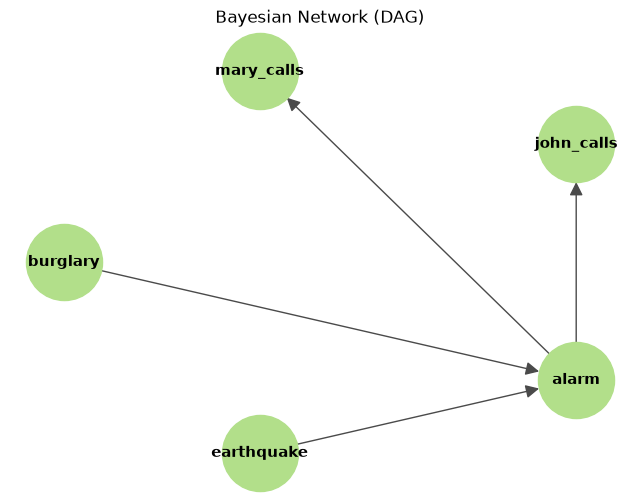

In [3]:
fig, ax = plt.subplots(figsize=(8, 6))
alarm_net.draw(ax=ax, layout='shell', node_color='#B2DF8A', node_size=3000, font_size=11)
plt.show()

## 2. D-Separation & Conditional Independence (BRML Section 3.3)

The DAG structure encodes conditional independencies through the **d-separation** criterion:
1. **Collider (v-structure)**: Burglary and Earthquake are marginally independent: $B \perp E \mid \emptyset$.
   However, conditioning on their common child (Alarm) makes them **dependent**: $B \not\perp E \mid A$.
2. **Markov Chain**: John and Mary only communicate through the Alarm: $J \perp M \mid A$.
   Without knowing if the alarm sounded, their calls are dependent: $J \not\perp M \mid \emptyset$.

In [4]:
print('=== D-Separation Queries ===')
print('1. Burglary independent of Earthquake?            ', alarm_net.is_independent('burglary', 'earthquake'))
print('2. Burglary independent of Earthquake given Alarm?', alarm_net.is_independent('burglary', 'earthquake', given='alarm'))
print('3. JohnCalls independent of MaryCalls given Alarm? ', alarm_net.is_independent('john_calls', 'mary_calls', given='alarm'))
print('4. JohnCalls independent of MaryCalls without Alarm?', alarm_net.is_independent('john_calls', 'mary_calls'))

=== D-Separation Queries ===
1. Burglary independent of Earthquake?             True
2. Burglary independent of Earthquake given Alarm? False
3. JohnCalls independent of MaryCalls given Alarm?  True
4. JohnCalls independent of MaryCalls without Alarm? False


## 3. Exact Inference via Variable Elimination

Suppose both John and Mary call to report hearing the alarm: $\text{Evidence} = \{J=\text{'yes'}, M=\text{'yes'}\}$.
What is the updated posterior probability of a Burglary, $P(B \mid J=\text{'yes'}, M=\text{'yes'})$?

Using `.query()`, the network uses **Variable Elimination** to sum out the unobserved hidden variables ($E$ and $A$).

In [5]:
post_b = alarm_net.query(target='burglary', evidence={'john_calls': 'yes', 'mary_calls': 'yes'})
print('Posterior Distribution for Burglary:')
print(post_b.data)
print(f"\nPrior Probability of Burglary:     {burglary.p(burglary='yes'):.4f} (0.1%)")
print(f"Posterior Probability (given J, M): {post_b.p(burglary='yes'):.4f} (28.4%)")

Posterior Distribution for Burglary:
burglary
yes    0.284172
no     0.715828
Name: p(burglary), dtype: float64

Prior Probability of Burglary:     0.0010 (0.1%)
Posterior Probability (given J, M): 0.2842 (28.4%)


## 4. Explaining Away: The Interplay of Causes

Now suppose we turn on the radio and confirm that a major **Earthquake** just struck ($E=\text{'yes'}$).
What happens to the probability of a burglary now?
Because an earthquake can explain the alarm ringing and John/Mary calling, it **explains away** the evidence for a burglary.

P(Burglary | JohnCalls, MaryCalls, Earthquake): 0.0033 (~0.7%)


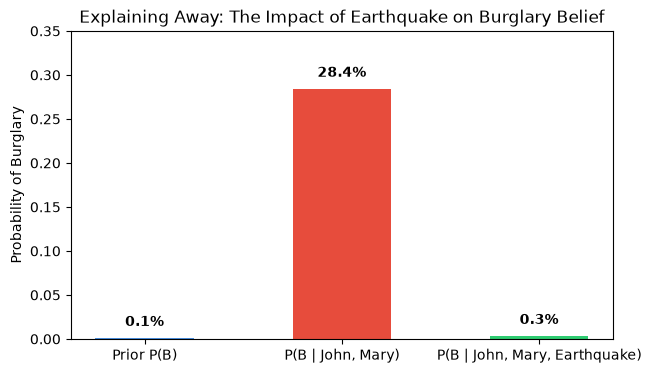

In [6]:
post_b_earthquake = alarm_net.query(
    target='burglary',
    evidence={'john_calls': 'yes', 'mary_calls': 'yes', 'earthquake': 'yes'}
)
p_explained_away = post_b_earthquake.p(burglary='yes')
print(f"P(Burglary | JohnCalls, MaryCalls, Earthquake): {p_explained_away:.4f} (~0.7%)")

# Visualizing the belief update
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(
    ['Prior P(B)', 'P(B | John, Mary)', 'P(B | John, Mary, Earthquake)'],
    [burglary.p(burglary='yes'), post_b.p(burglary='yes'), p_explained_away],
    color=['#4A90E2', '#E74C3C', '#2ECC71'],
    width=0.5
)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, yval + 0.01, f"{yval:.1%}", ha='center', va='bottom', fontweight='bold')
ax.set_ylabel('Probability of Burglary')
ax.set_title('Explaining Away: The Impact of Earthquake on Burglary Belief')
ax.set_ylim(0, 0.35)
plt.show()

## 5. The Asia / Chest Clinic Network (Lauritzen & Spiegelhalter / BRML Example 3.2)

The **Asia network** is one of the most famous benchmark belief networks in machine learning and medical informatics.
It models shortness of breath (**Dyspnoea**, $D$) resulting from either **Tuberculosis** ($T$), **Lung Cancer** ($L$), or **Bronchitis** ($B$):
- $A$: Visited Asia (increases risk of Tuberculosis)
- $S$: Smoker (increases risk of Lung Cancer and Bronchitis)
- $T$: Tuberculosis (depends on $A$)
- $L$: Lung Cancer (depends on $S$)
- $B$: Bronchitis (depends on $S$)
- $E$: Either Tuberculosis or Lung Cancer ($T \lor L$)
- $X$: Positive Chest X-Ray (depends on $E$)
- $D$: Dyspnoea (depends on $E$ and $B$)

Let us construct this 8-variable diagnostic network.

In [7]:
# 1. Priors
asia = Discrete.from_probs({'yes': 0.01, 'no': 0.99}, variables='asia')
smoke = Discrete.from_probs({'yes': 0.50, 'no': 0.50}, variables='smoke')

# 2. Tuberculosis | Asia
tub = Conditional.from_probs({
    ('yes', 'yes'): 0.05, ('no', 'yes'): 0.95,
    ('yes', 'no'):  0.01, ('no', 'no'):  0.99,
}, joint_variables='tub', conditional_variables='asia')

# 3. Lung Cancer | Smoke
cancer = Conditional.from_probs({
    ('yes', 'yes'): 0.10, ('no', 'yes'): 0.90,
    ('yes', 'no'):  0.01, ('no', 'no'):  0.99,
}, joint_variables='cancer', conditional_variables='smoke')

# 4. Bronchitis | Smoke
bronch = Conditional.from_probs({
    ('yes', 'yes'): 0.60, ('no', 'yes'): 0.40,
    ('yes', 'no'):  0.30, ('no', 'no'):  0.70,
}, joint_variables='bronch', conditional_variables='smoke')

# 5. Either (Tub or Cancer)
either = Conditional.from_probs({
    ('yes', 'yes', 'yes'): 1.0, ('no', 'yes', 'yes'): 0.0,
    ('yes', 'yes', 'no'):  1.0, ('no', 'yes', 'no'):  0.0,
    ('yes', 'no',  'yes'): 1.0, ('no', 'no',  'yes'): 0.0,
    ('yes', 'no',  'no'):  0.0, ('no', 'no',  'no'): 1.0,
}, joint_variables='either', conditional_variables=['tub', 'cancer'])

# 6. X-Ray | Either
xray = Conditional.from_probs({
    ('yes', 'yes'): 0.98, ('no', 'yes'): 0.02,
    ('yes', 'no'):  0.05, ('no', 'no'):  0.95,
}, joint_variables='xray', conditional_variables='either')

# 7. Dyspnoea | Either, Bronchitis
dysp = Conditional.from_probs({
    ('yes', 'yes', 'yes'): 0.90, ('no', 'yes', 'yes'): 0.10,
    ('yes', 'yes', 'no'):  0.70, ('no', 'yes', 'no'):  0.30,
    ('yes', 'no',  'yes'): 0.80, ('no', 'no',  'yes'): 0.20,
    ('yes', 'no',  'no'):  0.10, ('no', 'no',  'no'): 0.90,
}, joint_variables='dysp', conditional_variables=['either', 'bronch'])

asia_net = BayesianNetwork([asia, smoke, tub, cancer, bronch, either, xray, dysp])
print(asia_net)

BayesianNetwork(nodes=[asia, smoke, tub, cancer, bronch, either, xray, dysp], edges=8)


### Visualizing the Asia Network DAG

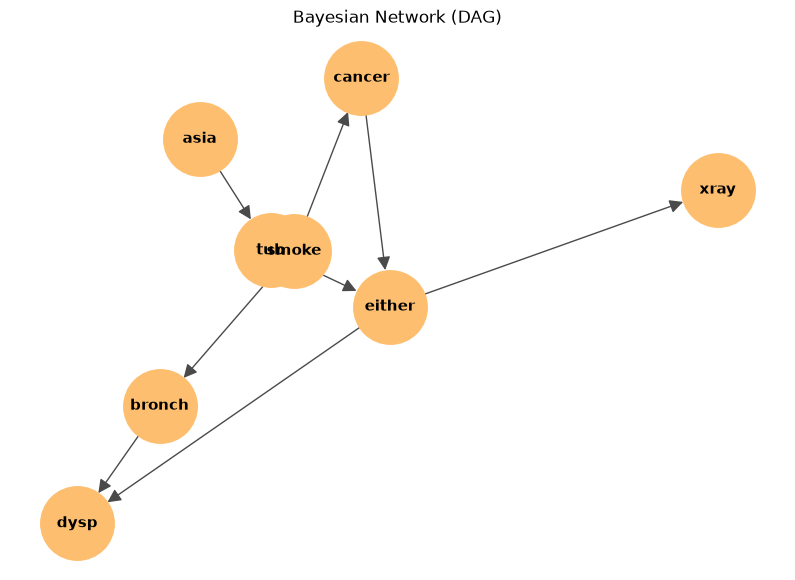

In [8]:
fig, ax = plt.subplots(figsize=(10, 7))
asia_net.draw(ax=ax, layout='spring', node_color='#FDBF6F', node_size=2800, font_size=11)
plt.show()

### Clinical Diagnosis Scenarios

Suppose a patient presents with shortness of breath (**Dyspnoea** = `yes`) and a **positive X-ray** (`yes`).
Let us evaluate the probability of Lung Cancer vs. Tuberculosis for this patient under different patient histories:
1. **Baseline**: Dyspnoea & Positive X-ray only.
2. **Smoker**: Patient is also known to be a smoker.
3. **Asia Traveler**: Patient recently returned from Asia.

In [9]:
# Scenario 1: Symptoms only (Dyspnoea + Positive X-ray)
p_cancer_s1 = asia_net.p('cancer', 'yes', given={'dysp': 'yes', 'xray': 'yes'})
p_tub_s1    = asia_net.p('tub', 'yes', given={'dysp': 'yes', 'xray': 'yes'})

# Scenario 2: Smoker
p_cancer_s2 = asia_net.p('cancer', 'yes', given={'dysp': 'yes', 'xray': 'yes', 'smoke': 'yes'})
p_tub_s2    = asia_net.p('tub', 'yes', given={'dysp': 'yes', 'xray': 'yes', 'smoke': 'yes'})

# Scenario 3: Non-smoker, visited Asia
p_cancer_s3 = asia_net.p('cancer', 'yes', given={'dysp': 'yes', 'xray': 'yes', 'smoke': 'no', 'asia': 'yes'})
p_tub_s3    = asia_net.p('tub', 'yes', given={'dysp': 'yes', 'xray': 'yes', 'smoke': 'no', 'asia': 'yes'})

print(f"Scenario 1 (Dysp + X-Ray):           Cancer = {p_cancer_s1:.1%}, Tuberculosis = {p_tub_s1:.1%}")
print(f"Scenario 2 (+ Smoker):               Cancer = {p_cancer_s2:.1%}, Tuberculosis = {p_tub_s2:.1%}")
print(f"Scenario 3 (+ Non-smoker, Visited Asia): Cancer = {p_cancer_s3:.1%}, Tuberculosis = {p_tub_s3:.1%}")

Scenario 1 (Dysp + X-Ray):           Cancer = 62.1%, Tuberculosis = 11.4%
Scenario 2 (+ Smoker):               Cancer = 72.4%, Tuberculosis = 7.5%
Scenario 3 (+ Non-smoker, Visited Asia): Cancer = 12.6%, Tuberculosis = 63.2%


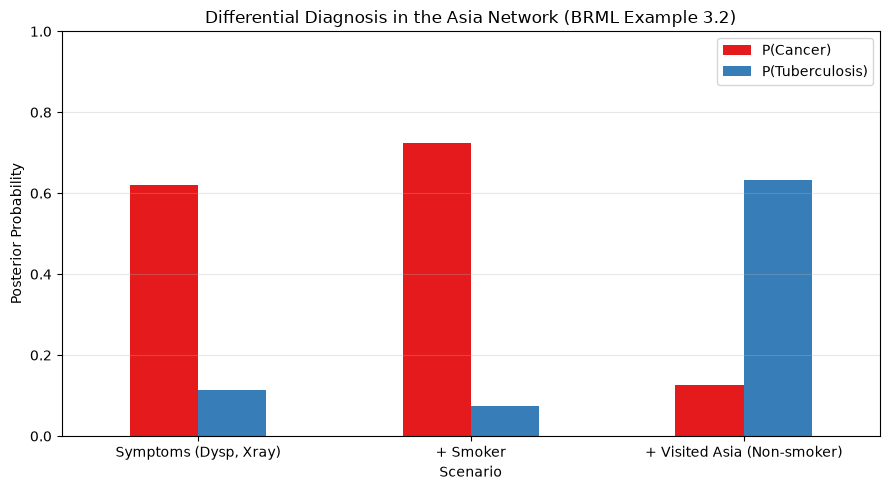

In [10]:
import pandas as pd
df_results = pd.DataFrame({
    'Scenario': ['Symptoms (Dysp, Xray)', '+ Smoker', '+ Visited Asia (Non-smoker)'],
    'P(Cancer)': [p_cancer_s1, p_cancer_s2, p_cancer_s3],
    'P(Tuberculosis)': [p_tub_s1, p_tub_s2, p_tub_s3]
})
ax = df_results.plot.bar(
    x='Scenario', y=['P(Cancer)', 'P(Tuberculosis)'],
    figsize=(9, 5), color=['#E41A1C', '#377EB8'], rot=0
)
ax.set_ylabel('Posterior Probability')
ax.set_title('Differential Diagnosis in the Asia Network (BRML Example 3.2)')
ax.set_ylim(0, 1.0)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Summary
In this notebook, we demonstrated:
- How `BayesianNetwork` automatically builds a DAG from local `Discrete` and `Conditional` CPTs.
- How **d-separation** correctly identifies conditional independencies (such as v-structures and explaining away).
- How **Variable Elimination** computes exact posterior queries $P(T \mid E=e)$ for high-dimensional models (like the 8-node Asia network) efficiently.